# 03 — Comparer la baseline et les modèles transférés

Ce notebook évalue sur **exactement les mêmes 16 475 images de validation** :

1. le CNN entraîné de zéro (notebook 01, baseline) ;
2. EfficientNetB0 avec backbone gelé (notebook 02, étape 1) ;
3. EfficientNetB0 fine-tuné (notebook 02, étape 2) ;
4. si disponible, la variante CLAHE du premier parcours (ablation, `archive_v1`).

Il produit le tableau de progression, les courbes d'apprentissage, l'analyse par classe, la matrice de
confusion du meilleur modèle, ses erreurs les plus confiantes et, si `data/raw_x_test.csv` existe, les
prédictions du jeu de test. Le meilleur modèle est choisi sur le F1 pondéré ; le F1 macro est surveillé
pour ne pas sacrifier les petites classes.


In [11]:
from pathlib import Path
import json
import os
import random

import certifi
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Python installé depuis python.org sur macOS ne référence pas toujours le trousseau
# système. On fournit à urllib/Keras un bundle CA explicite sans désactiver SSL.
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

def find_project_root() -> Path:
    """Permet d'exécuter le notebook depuis sa racine ou son propre dossier."""
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "data" / "raw_x.csv").exists() and (candidate / "images").exists():
            return candidate
    raise FileNotFoundError("Racine du projet introuvable (data/raw_x.csv et images/ attendus).")

ROOT = find_project_root()
DATA_DIR = ROOT / "data"
IMAGE_DIR = ROOT / "images" / "image_train"
ARTIFACTS_DIR = ROOT / "artifacts" / "image_classification"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("KERAS_HOME", str(ARTIFACTS_DIR / ".keras"))

print("Racine :", ROOT)
print("Artefacts :", ARTIFACTS_DIR)
print("Certificats SSL :", os.environ["SSL_CERT_FILE"])


Racine : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2
Artefacts : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification
Certificats SSL : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/.conda/rakuten-metal/lib/python3.10/site-packages/certifi/cacert.pem


In [12]:
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)

TARGET_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

with open(ARTIFACTS_DIR / "class_mapping.json", encoding="utf-8") as handle:
    class_mapping = json.load(handle)

index_to_code = [int(value) for value in class_mapping["index_to_code"]]
code_to_index = {code: index for index, code in enumerate(index_to_code)}
NUM_CLASSES = len(index_to_code)

manifest = pd.read_csv(ARTIFACTS_DIR / "image_manifest.csv")
manifest["class_index"] = manifest["prdtypecode"].map(code_to_index)
assert manifest["class_index"].notna().all()

def decode_resize(path, label, weight):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, *TARGET_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)  # Pixels dans [0, 255] : chaque modèle gère sa mise à l'échelle.
    return image, tf.cast(label, tf.int32), tf.cast(weight, tf.float32)

def make_dataset(frame, training=False, transform=None, weighted=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["class_index"].astype("int32").to_numpy()
    weights = frame["sample_weight"].astype("float32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, weights))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    if transform is not None:
        ds = ds.map(transform, num_parallel_calls=AUTOTUNE)
    if not weighted:
        ds = ds.map(lambda x, y, w: (x, y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_df = manifest.query("split == 'train'").copy()
val_df = manifest.query("split == 'validation'").copy()
print(f"Train={len(train_df):,} | Validation={len(val_df):,} | Classes={NUM_CLASSES}")


Train=65,900 | Validation=16,475 | Classes=27


In [13]:
category_names = {
    10: "Livres occasion",
    2280: "Journaux et revues occasion",
    2403: "Livres, BD et magazines",
    2522: "Fournitures papeterie et accessoires bureau",
    2705: "Livres neufs",
    40: "Jeux vidéos, CDs, équipements, câbles, neufs",
    50: "Accessoires gaming",
    60: "Consoles de jeu",
    2462: "Jeux vidéos occasion",
    2905: "Jeux vidéos pour PC",
    1140: "Figurines, objets pop culture",
    1160: "Cartes de jeux",
    1180: "Figurines et jeux de rôles",
    1280: "Jouets enfants",
    1281: "Jeux société enfants",
    1300: "Modélisme",
    1302: "Jeux de plein air, habits",
    1560: "Mobilier général",
    2582: "Mobilier de jardin",
    1320: "Puériculture, accessoires bébé",
    2220: "Animalerie",
    2583: "Piscine et accessoires",
    2585: "Outillage de jardin, équipements extérieurs",
    1920: "Linge de maison, oreillers, coussins",
    2060: "Décoration",
    1301: "Chaussettes bébés, petites photos",
    1940: "Confiserie",
}
missing_category_names = sorted(set(index_to_code) - set(category_names))
if missing_category_names:
    raise ValueError(f"Libellés manquants pour les catégories : {missing_category_names}")
readable_class_labels = [f"{code} — {category_names[code]}" for code in index_to_code]

def short_label(class_index):
    code = index_to_code[int(class_index)]
    return f"{code} {category_names[code]}"


In [14]:
import cv2
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

def build_legacy_efficientnet():
    """Architecture du premier run EfficientNet, pour charger ses poids sauvés par un Keras plus récent."""
    augmentation = keras.Sequential(
        [
            layers.RandomRotation(0.03, fill_mode="reflect", seed=SEED),
            layers.RandomZoom(0.10, fill_mode="reflect", seed=SEED),
            layers.RandomContrast(0.10, seed=SEED),
        ],
        name="augmentation",
    )
    inputs = keras.Input(shape=(*TARGET_SIZE, 3), name="image")
    x = augmentation(inputs)
    backbone = keras.applications.EfficientNetB0(
        include_top=False, weights=None, input_shape=(*TARGET_SIZE, 3)
    )
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(0.30, seed=SEED)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="prdtypecode")(x)
    return keras.Model(inputs, outputs)

def load_evaluation_model(path):
    try:
        return keras.models.load_model(path, compile=False)
    except TypeError as error:
        # Keras 3.15 ajoute ces champs à VarianceScaling ; Keras 3.12 (Metal)
        # ne sait pas les désérialiser. Les poids restent compatibles.
        if "input_axes" not in str(error) and "output_axes" not in str(error):
            raise
        print(f"Chargement rétrocompatible de {path}")
        model = build_legacy_efficientnet()
        model.load_weights(path)
        return model

def clahe_numpy(image):
    image_uint8 = np.clip(image, 0, 255).astype(np.uint8)
    lab = cv2.cvtColor(image_uint8, cv2.COLOR_RGB2LAB)
    lightness, channel_a, channel_b = cv2.split(lab)
    if float(lightness.std()) >= 40.0:
        return image_uint8.astype(np.float32)
    enhanced = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lightness)
    return cv2.cvtColor(
        cv2.merge((enhanced, channel_a, channel_b)), cv2.COLOR_LAB2RGB
    ).astype(np.float32)

def apply_clahe_tf(image, label, weight):
    image = tf.numpy_function(clahe_numpy, [image], Tout=tf.float32)
    image.set_shape((*TARGET_SIZE, 3))
    return image, label, weight

def first_existing(*paths):
    return next((path for path in paths if path.exists()), None)

TRANSFER_DIR = ARTIFACTS_DIR / "efficientnet_transfer"
# Premier run EfficientNet (notebooks archive_v1) : modèle fine-tuné disponible, sans checkpoint de phase 1.
LEGACY_TRANSFER_DIR = ARTIFACTS_DIR / "efficientnet_baseline"

candidate_experiments = {
    "cnn_scratch": {
        "label": "1. CNN entraîné de zéro",
        "run_dir": ARTIFACTS_DIR / "cnn_scratch",
        "path": ARTIFACTS_DIR / "cnn_scratch" / "best_model.keras",
        "transform": None,
        "gradcam_layer": "features",
    },
    "efficientnet_frozen": {
        "label": "2. EfficientNetB0 gelé (feature extraction)",
        "run_dir": TRANSFER_DIR,
        "path": TRANSFER_DIR / "feature_extraction_best.keras",
        "transform": None,
        "gradcam_layer": "efficientnetb0",
    },
    "efficientnet_finetuned": {
        "label": "3. EfficientNetB0 fine-tuné",
        "run_dir": TRANSFER_DIR if (TRANSFER_DIR / "best_model.keras").exists() else LEGACY_TRANSFER_DIR,
        "path": first_existing(TRANSFER_DIR / "best_model.keras", LEGACY_TRANSFER_DIR / "best_model.keras"),
        "transform": None,
        "gradcam_layer": "efficientnetb0",
    },
    "efficientnet_clahe": {
        "label": "Ablation : fine-tuné + CLAHE",
        "run_dir": ARTIFACTS_DIR / "efficientnet_clahe",
        "path": ARTIFACTS_DIR / "efficientnet_clahe" / "best_model.keras",
        "transform": apply_clahe_tf,
        "gradcam_layer": "efficientnetb0",
    },
}
experiments = {
    name: run for name, run in candidate_experiments.items()
    if run["path"] is not None and run["path"].exists()
}
for name, run in candidate_experiments.items():
    status = run["path"] if name in experiments else "absent"
    print(f"{run['label']:<45} {status}")

PREDICTIONS_DIR = ARTIFACTS_DIR / "predictions"
PREDICTIONS_DIR.mkdir(exist_ok=True)


1. CNN entraîné de zéro                       /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification/cnn_scratch/best_model.keras
2. EfficientNetB0 gelé (feature extraction)   /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification/efficientnet_transfer/feature_extraction_best.keras
3. EfficientNetB0 fine-tuné                   /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification/efficientnet_transfer/best_model.keras
Ablation : fine-tuné + CLAHE                  /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification/efficientnet_clahe/best_model.keras


In [15]:
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, top_k_accuracy_score


## 1. Prédictions sur la validation

Les probabilités sont sauvegardées dans `predictions/` pour être réutilisées par le notebook 04.


In [16]:
required = {"cnn_scratch", "efficientnet_finetuned"}
if not required.issubset(experiments):
    raise FileNotFoundError("Exécuter d'abord les notebooks 01 et 02 : " + ", ".join(sorted(required - set(experiments))))
if "efficientnet_frozen" not in experiments:
    print("Checkpoint de feature extraction absent : exécuter le notebook 02 pour compléter la progression.")

y_true = val_df["class_index"].to_numpy()
predictions = {}
loaded_models = {}
for name, run in experiments.items():
    print(f"\n{run['label']}")
    model = load_evaluation_model(run["path"])
    ds = make_dataset(val_df, transform=run["transform"], weighted=False)
    probabilities = model.predict(ds, verbose=1)
    predictions[name] = {"probabilities": probabilities, "labels": probabilities.argmax(axis=1)}
    loaded_models[name] = model
    np.savez_compressed(
        PREDICTIONS_DIR / f"val_{name}.npz", Id=val_df["Id"].to_numpy(), probabilities=probabilities
    )



1. CNN entraîné de zéro
515/515 ━━━━━━━━━━━━━━━━━━━━ 16s 29ms/step

2. EfficientNetB0 gelé (feature extraction)
515/515 ━━━━━━━━━━━━━━━━━━━━ 68s 118ms/step

3. EfficientNetB0 fine-tuné
515/515 ━━━━━━━━━━━━━━━━━━━━ 61s 112ms/step

Ablation : fine-tuné + CLAHE
515/515 ━━━━━━━━━━━━━━━━━━━━ 62s 113ms/step


## 2. Tableau de progression

Les paramètres et durées proviennent des fichiers `run_summary.json` écrits par les notebooks 01 et 02
(absents pour les runs du premier parcours).


In [17]:
def run_info(name):
    path = experiments[name]["run_dir"] / "run_summary.json"
    summary = json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}
    if name == "efficientnet_frozen":
        summary = summary.get("feature_extraction", {})
    elif name == "efficientnet_finetuned" and "fine_tuning" in summary:
        frozen_time = summary.get("feature_extraction", {}).get("train_time_min", 0)
        summary = dict(summary["fine_tuning"])
        summary["train_time_min"] = round(summary["train_time_min"] + frozen_time, 1)
    elif name == "efficientnet_finetuned":
        summary = {}
    return summary

rows = []
for name, result in predictions.items():
    info = run_info(name)
    rows.append({
        "experiment": name,
        "modèle": experiments[name]["label"],
        "accuracy": accuracy_score(y_true, result["labels"]),
        "top3_accuracy": top_k_accuracy_score(
            y_true, result["probabilities"], k=3, labels=np.arange(NUM_CLASSES)
        ),
        "f1_weighted": f1_score(y_true, result["labels"], average="weighted"),
        "f1_macro": f1_score(y_true, result["labels"], average="macro"),
        "paramètres": loaded_models[name].count_params(),
        "paramètres entraînés": info.get("params_trainable"),
        "durée (min)": info.get("train_time_min"),
    })
metrics = pd.DataFrame(rows).set_index("experiment")
metrics.to_csv(ARTIFACTS_DIR / "model_comparison.csv")
display(metrics.style.format({
    "accuracy": "{:.4f}", "top3_accuracy": "{:.4f}", "f1_weighted": "{:.4f}", "f1_macro": "{:.4f}",
    "paramètres": "{:,.0f}", "paramètres entraînés": "{:,.0f}", "durée (min)": "{:.0f}",
}, na_rep="–"))

CHAMPION = metrics["f1_weighted"].idxmax()
BASELINE = "cnn_scratch"
gain = metrics.loc[CHAMPION, "f1_weighted"] - metrics.loc[BASELINE, "f1_weighted"]
print(f"Champion selon le F1 pondéré : {experiments[CHAMPION]['label']}")
print(f"Gain par rapport à la baseline : {gain:+.4f} de F1 pondéré")


,modèle,accuracy,top3_accuracy,f1_weighted,f1_macro,paramètres,paramètres entraînés,durée (min)
experiment,,,,,,,,
cnn_scratch,1. CNN entraîné de zéro,0.5411,0.7451,0.5196,0.4499,"987,643","986,171",124
efficientnet_frozen,2. EfficientNetB0 gelé (feature extraction),0.5731,0.7908,0.5625,0.5221,"4,084,158","34,587",44
efficientnet_finetuned,3. EfficientNetB0 fine-tuné,0.6122,0.8207,0.6049,0.5612,"4,084,158","1,517,947",116
efficientnet_clahe,Ablation : fine-tuné + CLAHE,0.6106,0.8245,0.6032,0.5603,"4,084,158",–,–


Champion selon le F1 pondéré : 3. EfficientNetB0 fine-tuné
Gain par rapport à la baseline : +0.0853 de F1 pondéré


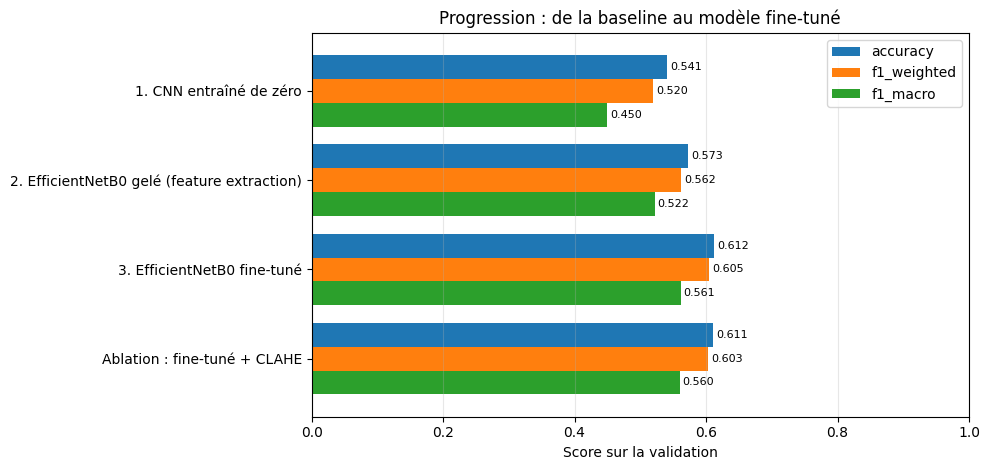

In [18]:
plot_metrics = metrics[["accuracy", "f1_weighted", "f1_macro"]].rename(index=lambda name: experiments[name]["label"])
ax = plot_metrics.plot.barh(figsize=(10, 1.2 + 0.9 * len(plot_metrics)), width=0.8)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Score sur la validation")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.set_title("Progression : de la baseline au modèle fine-tuné")
plt.tight_layout()
plt.show()


## 3. Courbes d'apprentissage

Accuracy de validation par époque. La ligne pointillée marque le début du fine-tuning d'EfficientNet.


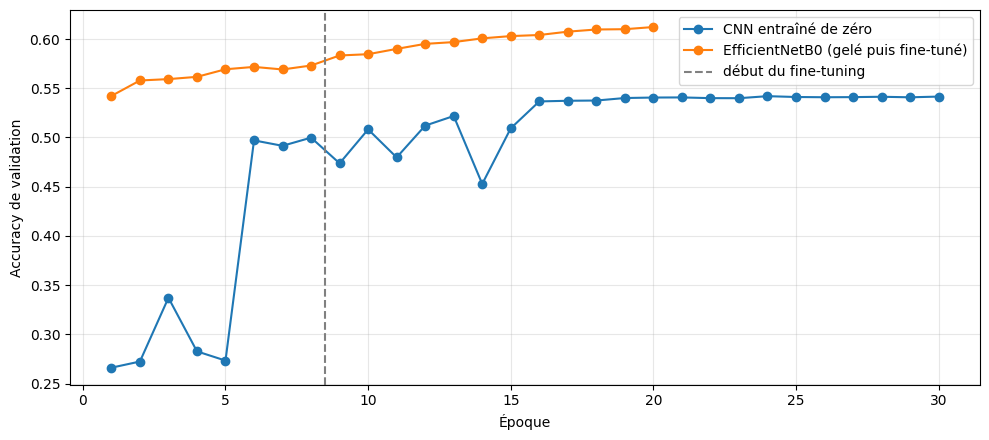

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.5))
curves = {
    "CNN entraîné de zéro": experiments["cnn_scratch"]["run_dir"],
    "EfficientNetB0 (gelé puis fine-tuné)": experiments["efficientnet_finetuned"]["run_dir"],
}
for label, run_dir in curves.items():
    log_path = run_dir / "training_log.csv"
    # Relancer un notebook d'entraînement vide ce journal dès la première époque.
    if not log_path.exists() or log_path.stat().st_size == 0:
        print(f"Journal absent ou vide, courbe ignorée : {log_path}")
        continue
    log = pd.read_csv(log_path)
    ax.plot(log["epoch"] + 1, log["val_accuracy"], marker="o", label=label)
transfer_summary = experiments["efficientnet_finetuned"]["run_dir"] / "run_summary.json"
if transfer_summary.exists():
    boundary = json.loads(transfer_summary.read_text())["feature_extraction"]["epochs_run"]
    ax.axvline(boundary + 0.5, color="grey", linestyle="--", label="début du fine-tuning")
ax.set_xlabel("Époque")
ax.set_ylabel("Accuracy de validation")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## 4. Analyse par classe

Le gain du transfert n'est pas uniforme : la comparaison par classe montre quelles catégories en
profitent le plus, et lesquelles restent difficiles même pour le meilleur modèle.


In [20]:
per_class = pd.DataFrame({
    "prdtypecode": index_to_code,
    "category_name": [category_names[code] for code in index_to_code],
    "support": np.bincount(y_true, minlength=NUM_CLASSES),
})
for name, result in predictions.items():
    per_class[f"f1_{name}"] = f1_score(
        y_true, result["labels"], labels=np.arange(NUM_CLASSES), average=None, zero_division=0
    )
per_class["gain_transfert"] = per_class[f"f1_{CHAMPION}"] - per_class["f1_cnn_scratch"]
per_class = per_class.sort_values("gain_transfert", ascending=False)
per_class.to_csv(ARTIFACTS_DIR / "per_class_comparison.csv", index=False)
display(per_class.style.format({column: "{:.3f}" for column in per_class.columns if column.startswith(("f1_", "gain"))}))


,prdtypecode,category_name,support,f1_cnn_scratch,f1_efficientnet_frozen,f1_efficientnet_finetuned,f1_efficientnet_clahe,gain_transfert
10,1301,"Chaussettes bébés, petites photos",150,0.182,0.549,0.563,0.582,0.381
17,2220,Animalerie,164,0.088,0.403,0.437,0.426,0.349
6,1180,Figurines et jeux de rôles,148,0.088,0.423,0.409,0.407,0.321
24,2585,"Outillage de jardin, équipements extérieurs",489,0.136,0.303,0.362,0.362,0.226
2,50,Accessoires gaming,320,0.207,0.401,0.424,0.420,0.217
11,1302,"Jeux de plein air, habits",488,0.192,0.351,0.409,0.389,0.217
3,60,Consoles de jeu,164,0.495,0.650,0.671,0.673,0.176
12,1320,"Puériculture, accessoires bébé",636,0.308,0.451,0.474,0.461,0.166
4,1140,"Figurines, objets pop culture",510,0.482,0.597,0.638,0.643,0.156
15,1940,Confiserie,156,0.465,0.605,0.606,0.610,0.141


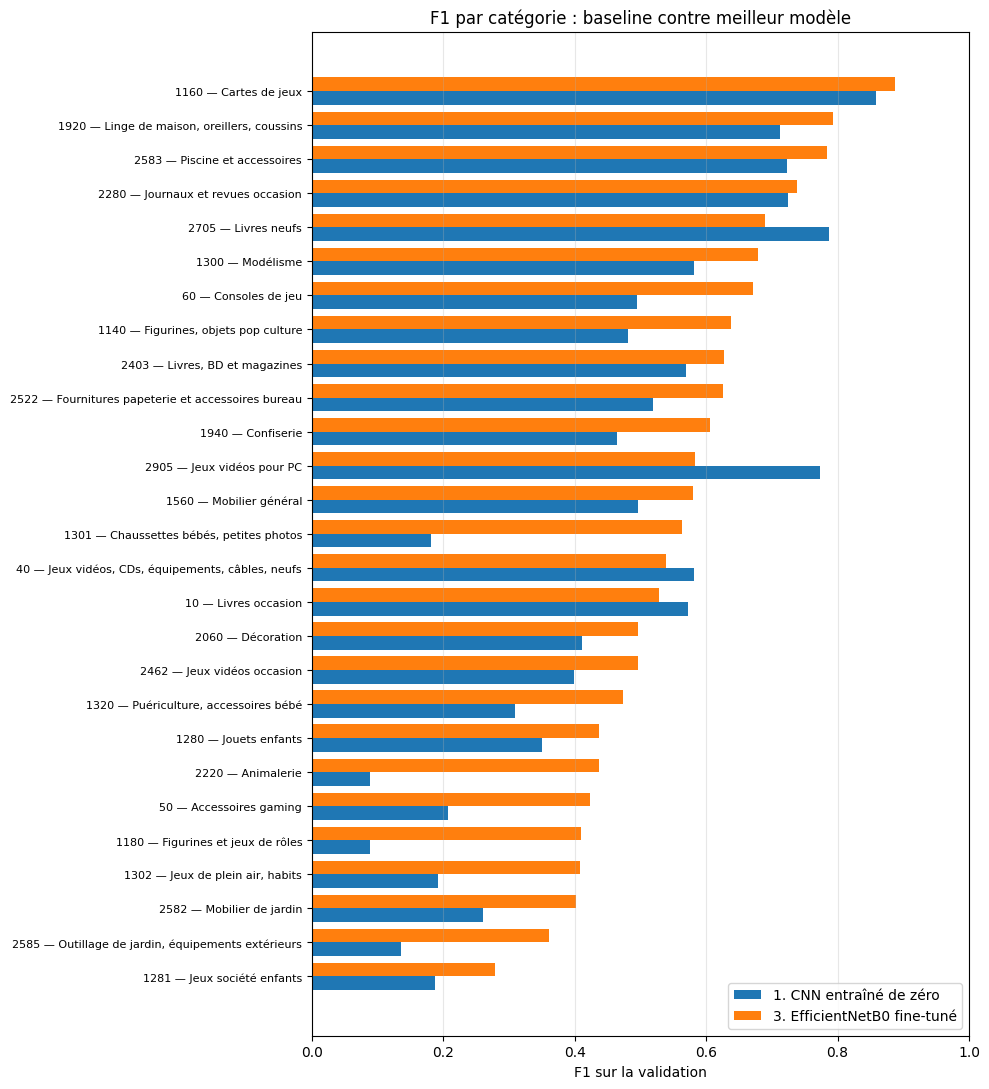

In [21]:
ordered = per_class.sort_values(f"f1_{CHAMPION}")
labels = [f"{code} — {name}" for code, name in zip(ordered["prdtypecode"], ordered["category_name"])]
positions = np.arange(len(ordered))
fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(positions - 0.2, ordered["f1_cnn_scratch"], height=0.4, label=experiments["cnn_scratch"]["label"])
ax.barh(positions + 0.2, ordered[f"f1_{CHAMPION}"], height=0.4, label=experiments[CHAMPION]["label"])
ax.set_yticks(positions, labels, fontsize=8)
ax.set_xlim(0, 1)
ax.set_xlabel("F1 sur la validation")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")
ax.set_title("F1 par catégorie : baseline contre meilleur modèle")
plt.tight_layout()
plt.show()


## 5. Matrice de confusion et confusions principales du meilleur modèle


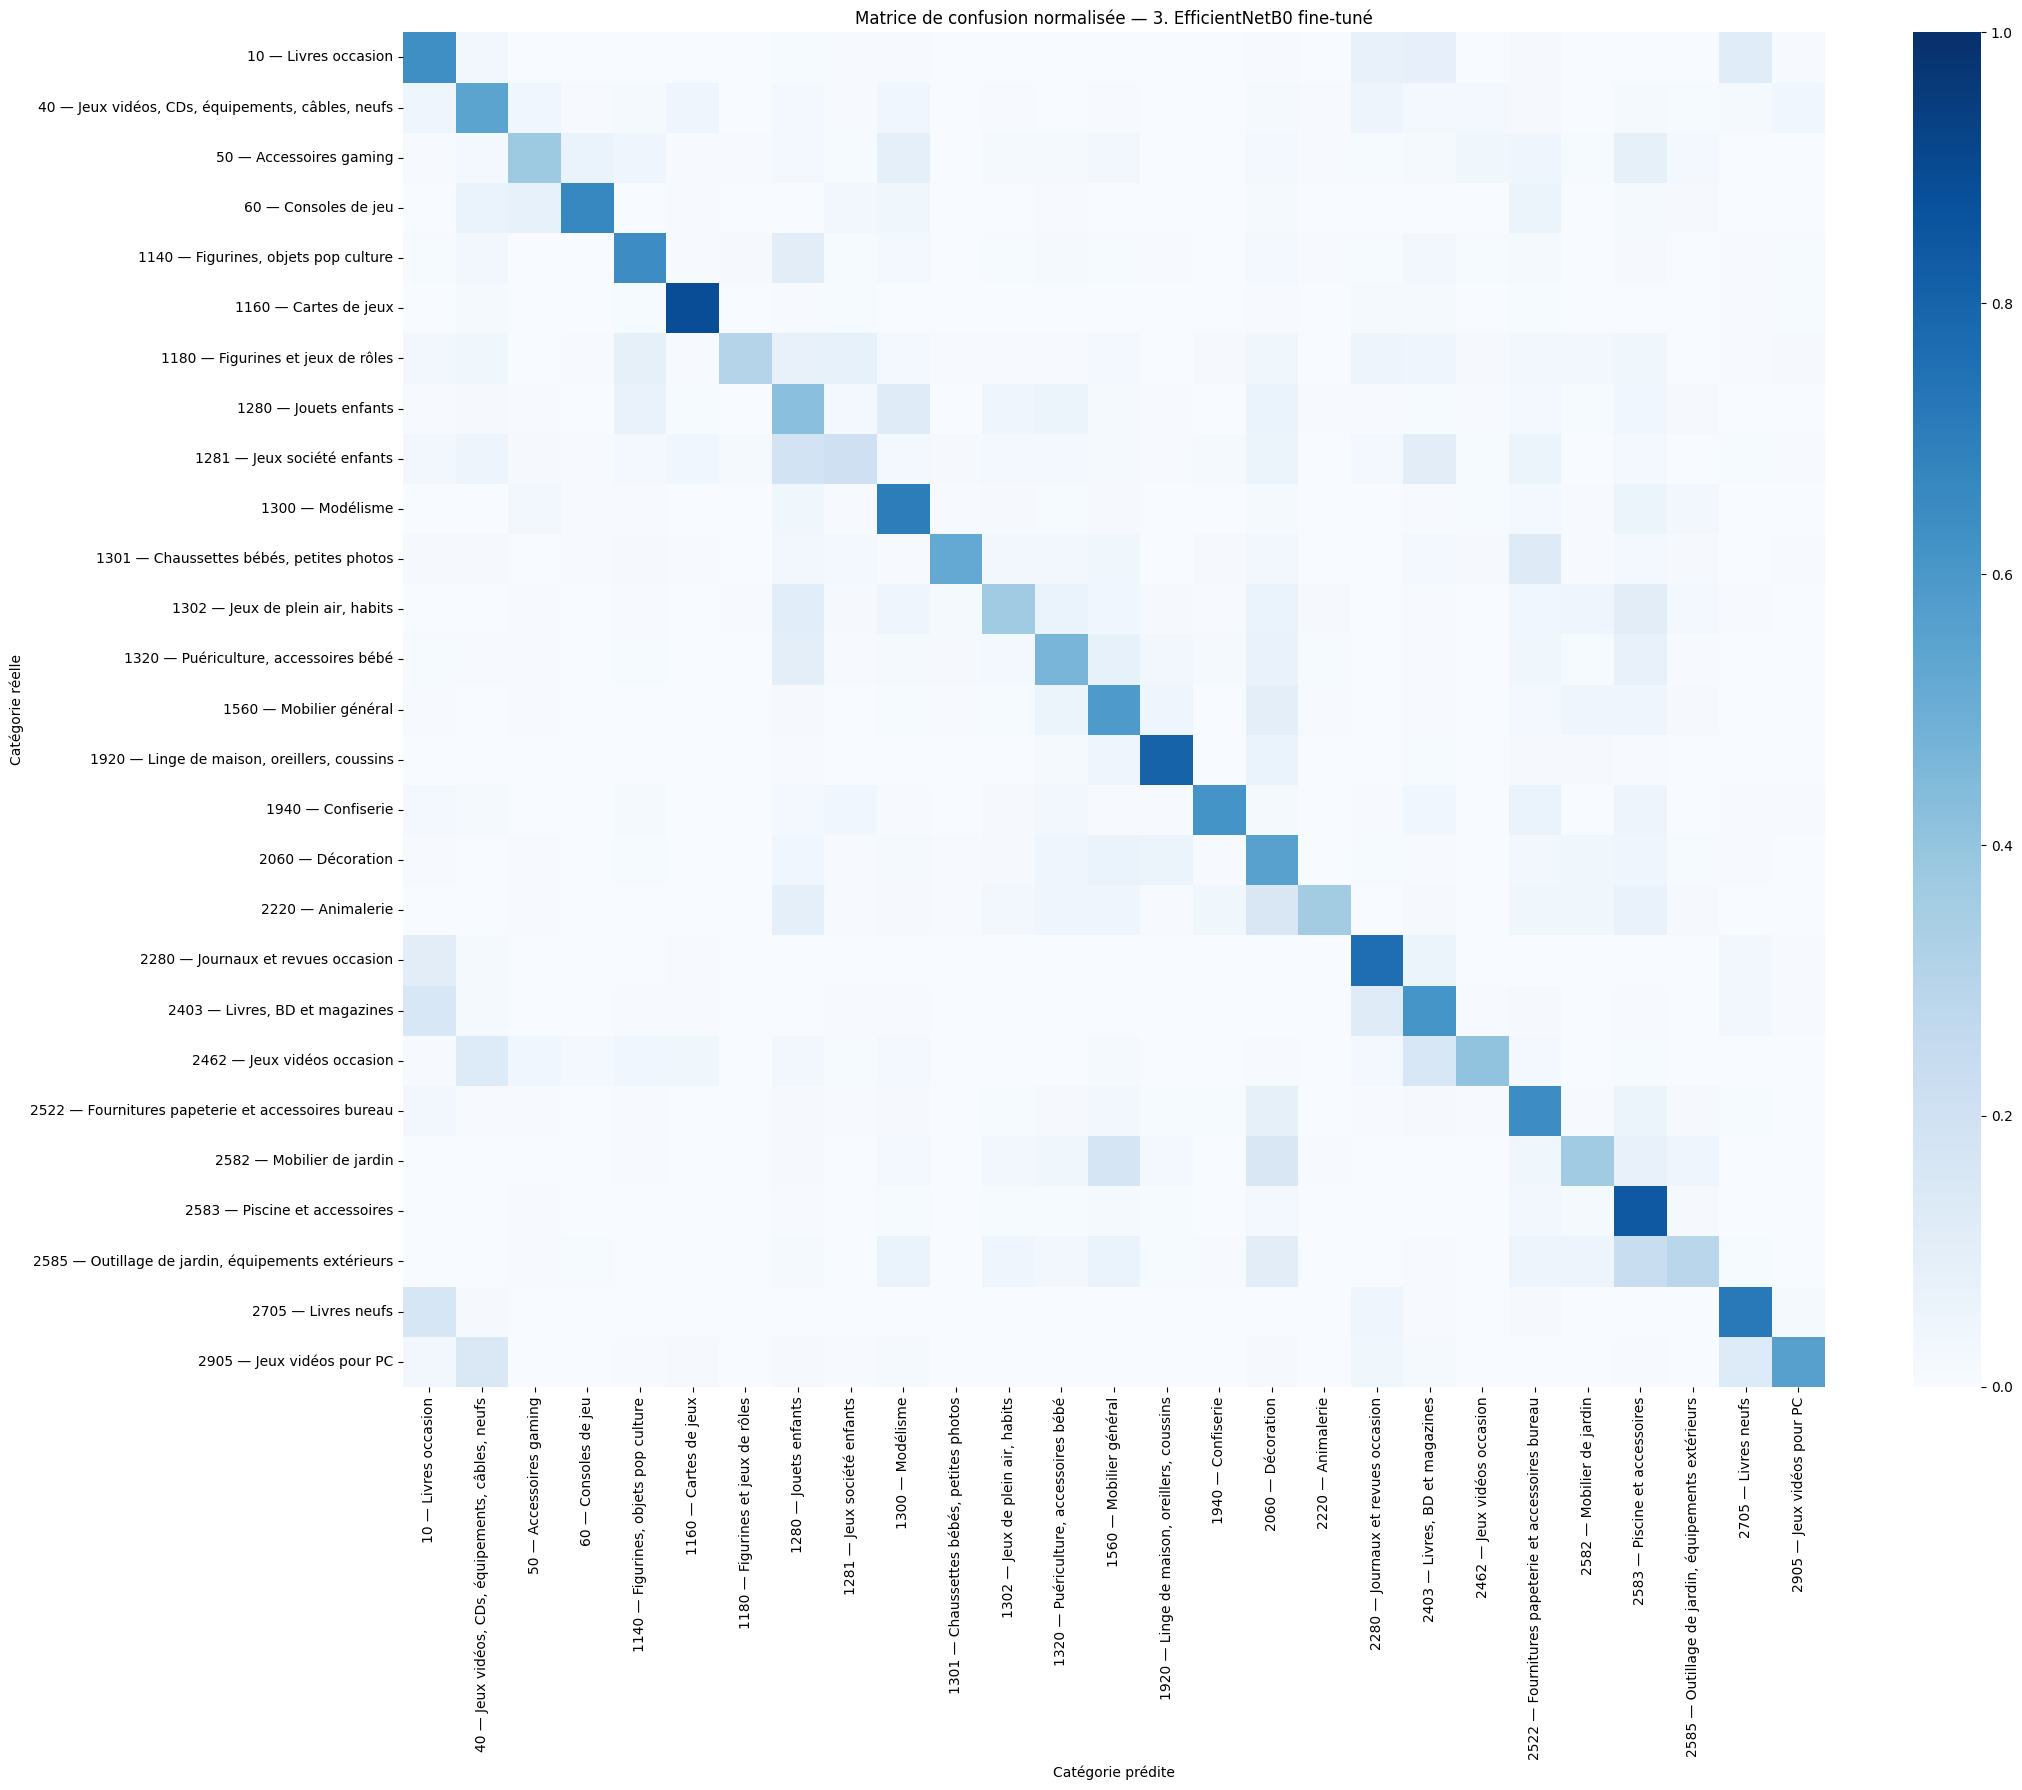

catégorie réelle,prédite à tort,images,part de la classe réelle
"2403 — Livres, BD et magazines",10 — Livres occasion,149,15.8%
"2585 — Outillage de jardin, équipements extérieurs",2583 — Piscine et accessoires,115,23.5%
"2403 — Livres, BD et magazines",2280 — Journaux et revues occasion,111,11.7%
1280 — Jouets enfants,1300 — Modélisme,109,12.2%
1560 — Mobilier général,2060 — Décoration,102,10.2%
2280 — Journaux et revues occasion,10 — Livres occasion,100,10.6%
2705 — Livres neufs,10 — Livres occasion,90,16.5%
2582 — Mobilier de jardin,1560 — Mobilier général,86,17.1%
2522 — Fournitures papeterie et accessoires bureau,2060 — Décoration,85,8.7%
2582 — Mobilier de jardin,2060 — Décoration,77,15.3%


In [22]:
champion_pred = predictions[CHAMPION]["labels"]
matrix = confusion_matrix(y_true, champion_pred, labels=np.arange(NUM_CLASSES), normalize="true")
plt.figure(figsize=(22, 18))
sns.heatmap(
    matrix, cmap="Blues", vmin=0, vmax=1,
    xticklabels=readable_class_labels, yticklabels=readable_class_labels,
)
plt.title(f"Matrice de confusion normalisée — {experiments[CHAMPION]['label']}")
plt.xlabel("Catégorie prédite")
plt.ylabel("Catégorie réelle")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

counts = confusion_matrix(y_true, champion_pred, labels=np.arange(NUM_CLASSES))
pairs = [
    {
        "catégorie réelle": readable_class_labels[i],
        "prédite à tort": readable_class_labels[j],
        "images": int(counts[i, j]),
        "part de la classe réelle": matrix[i, j],
    }
    for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j
]
top_confusions = pd.DataFrame(pairs).sort_values("images", ascending=False).head(10)
top_confusions.to_csv(ARTIFACTS_DIR / "top_confusions.csv", index=False)
display(top_confusions.style.format({"part de la classe réelle": "{:.1%}"}).hide(axis="index"))


## 6. Erreurs les plus confiantes

Ces exemples révèlent souvent des labels ambigus, des images peu informatives ou des confusions métier
récurrentes. Le notebook 04 montre, avec Grad-CAM, sur quelles zones le modèle s'est appuyé.


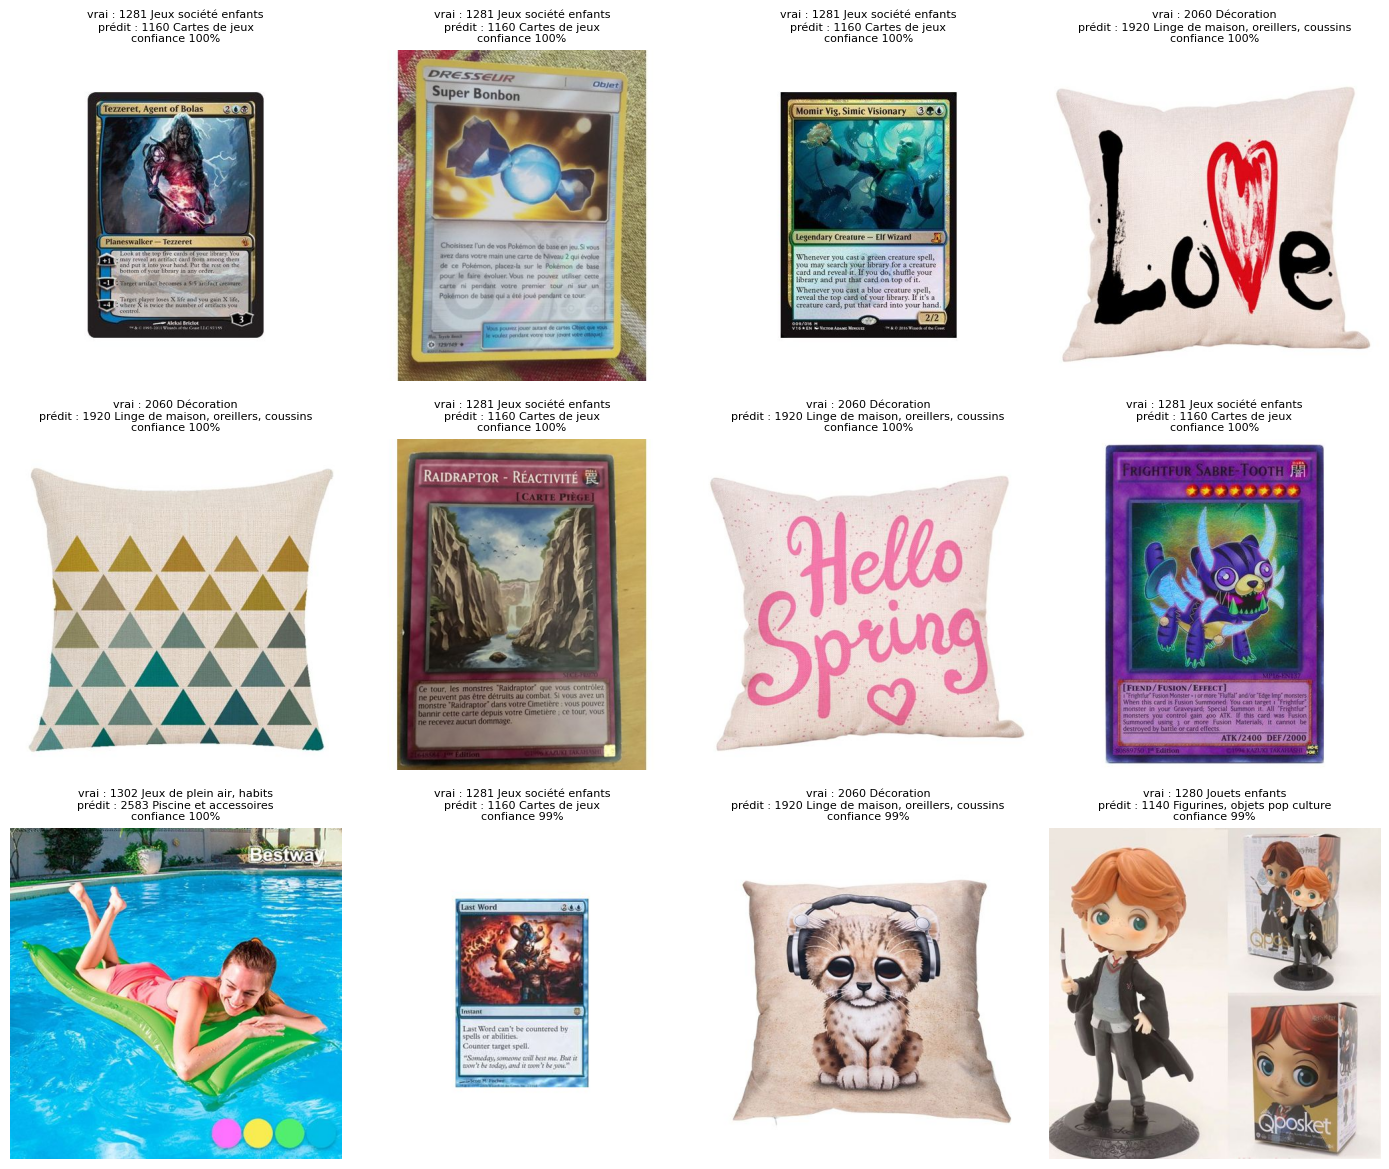

In [23]:
champion_proba = predictions[CHAMPION]["probabilities"]
errors = val_df.copy().reset_index(drop=True)
errors["true_index"] = y_true
errors["pred_index"] = champion_pred
errors["confidence"] = champion_proba.max(axis=1)
errors = errors.query("true_index != pred_index").sort_values("confidence", ascending=False)

fig, axes = plt.subplots(3, 4, figsize=(14, 12))
for ax, row in zip(axes.flat, errors.head(12).itertuples()):
    ax.imshow(plt.imread(row.image_path))
    ax.set_title(
        f"vrai : {short_label(row.true_index)}\n"
        f"prédit : {short_label(row.pred_index)}\n"
        f"confiance {row.confidence:.0%}", fontsize=8,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()


## 7. Prédire le jeu de test (optionnel)

Cette section attend `data/raw_x_test.csv` avec les colonnes `Id`, `imageid` et `productid`. Elle produit
`submission_image.csv` au format `Id,prdtypecode` et `predictions_image_labeled.csv` avec le libellé métier.


In [24]:
TEST_CSV = DATA_DIR / "raw_x_test.csv"
if not TEST_CSV.exists():
    print("Étape ignorée : ajouter", TEST_CSV, "pour générer les prédictions de test.")
else:
    test = pd.read_csv(TEST_CSV)
    required_columns = {"Id", "imageid", "productid"}
    assert required_columns.issubset(test.columns), required_columns - set(test.columns)
    test["image_path"] = test.apply(
        lambda row: str((ROOT / "images" / "image_test" /
            f"image_{row.imageid}_product_{row.productid}.jpg").resolve()), axis=1
    )
    assert test["image_path"].map(os.path.isfile).all()
    test["class_index"] = 0
    test["sample_weight"] = 1.0

    champion_run = experiments[CHAMPION]
    test_ds = make_dataset(test, transform=champion_run["transform"], weighted=False)
    test_probabilities = loaded_models[CHAMPION].predict(test_ds, verbose=1)
    test_codes = [index_to_code[index] for index in test_probabilities.argmax(axis=1)]
    submission = pd.DataFrame({"Id": test["Id"], "prdtypecode": test_codes})
    submission.to_csv(ARTIFACTS_DIR / "submission_image.csv", index=False)

    labeled_predictions = submission.copy()
    labeled_predictions["category_name"] = labeled_predictions["prdtypecode"].map(category_names)
    labeled_predictions.to_csv(ARTIFACTS_DIR / "predictions_image_labeled.csv", index=False)
    display(labeled_predictions.head())


Étape ignorée : ajouter /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/data/raw_x_test.csv pour générer les prédictions de test.
